## Quick AI Note:

Some code looks AI, when it's simply VScode autofill. Code produced by generative AI will have a comment left above it. 
I ascertained correctness of my AI code by comparing the code with notebook code and comparing visualizations/output with notebook output.

In [12]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.compose import make_column_transformer
from sklearn.feature_selection import SequentialFeatureSelector, RFE, RFECV
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import (train_test_split, KFold, RepeatedKFold,
                                     LeaveOneOut, cross_val_score)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import (FunctionTransformer, PolynomialFeatures,
                                SplineTransformer, StandardScaler, OneHotEncoder)

In [13]:
bike = pd.read_csv("C:\\Users\\witze\\Downloads\\DS6021_F26\\data\\bike-sharing-daily.csv")
bike.head(10)

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600
5,6,2011-01-06,1,0,1,0,4,1,1,0.204348,0.233209,0.518261,0.089565,88,1518,1606
6,7,2011-01-07,1,0,1,0,5,1,2,0.196522,0.208839,0.498696,0.168726,148,1362,1510
7,8,2011-01-08,1,0,1,0,6,0,2,0.165000,0.162254,0.535833,0.266804,68,891,959
8,9,2011-01-09,1,0,1,0,0,0,1,0.138333,0.116175,0.434167,0.361950,54,768,822
9,10,2011-01-10,1,0,1,0,1,1,1,0.150833,0.150888,0.482917,0.223267,41,1280,1321


In [14]:
auto = pd.read_csv("C:\\Users\\witze\\Downloads\\DS6021_F26\\data\\Auto.csv", na_values="?").dropna().reset_index(drop=True)
auto.head(10)

,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,1,ford torino
5,15.0,8,429.0,198.0,4341,10.0,70,1,ford galaxie 500
6,14.0,8,454.0,220.0,4354,9.0,70,1,chevrolet impala
7,14.0,8,440.0,215.0,4312,8.5,70,1,plymouth fury iii
8,14.0,8,455.0,225.0,4425,10.0,70,1,pontiac catalina
9,15.0,8,390.0,190.0,3850,8.5,70,1,amc ambassador dpl


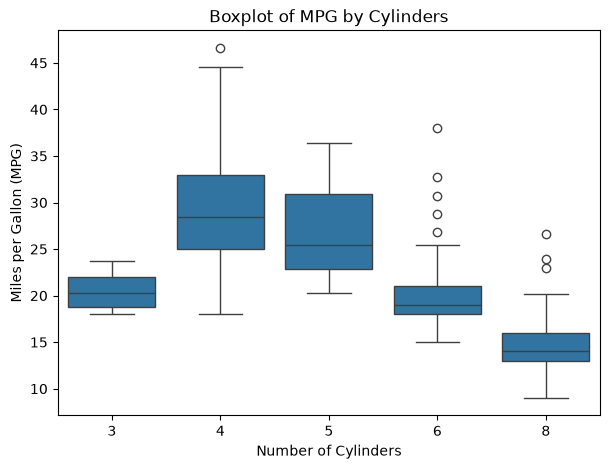

In [15]:
# Part 1
plt.figure(figsize=(7, 5))
sns.boxplot(x="cylinders", y="mpg", data=auto)
plt.title("Boxplot of MPG by Cylinders")
plt.xlabel("Number of Cylinders")
plt.ylabel("Miles per Gallon (MPG)")
plt.show()

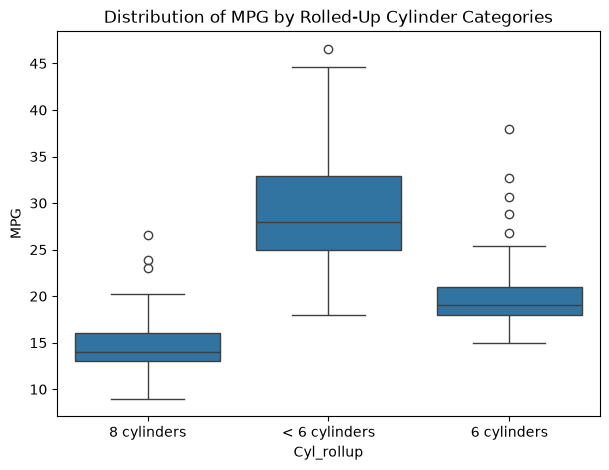

In [16]:
cyl_map = {
    3: '< 6 cylinders',
    4: '< 6 cylinders',
    5: '< 6 cylinders',
    6: '6 cylinders',
    8: '8 cylinders'
}

auto['cyl_rollup'] = auto['cylinders'].map(cyl_map)

plt.figure(figsize=(7, 5))
sns.boxplot(x='cyl_rollup', y='mpg', data=auto)
plt.title('Distribution of MPG by Rolled-Up Cylinder Categories')
plt.xlabel('Cyl_rollup')
plt.ylabel('MPG')
plt.show()

## 1.1
(a) I'm seeing 5 unique cylinder counts recorded.

(c) I'm noticing a significally higher MPG amongst the cars with less than 6 cylinders than the next two categories. In fact, it seems MPG increases as the amount of cylinders decreases.

(d) The "name" variable should be dropped from the dataset because every name is unique and doesn't provide any predictive value to our model.

In [17]:
y = auto['mpg']
X = auto[['displacement', 'horsepower', 'weight', 'acceleration', 'year']]
cv = KFold(n_splits=5, shuffle=True, random_state=42)

for k in range(1, 5):
    forward = make_pipeline(
        StandardScaler(),
        SequentialFeatureSelector(LinearRegression(), n_features_to_select=k,
                                  direction="forward", cv=cv,
                                  scoring="neg_root_mean_squared_error"),
        LinearRegression())
    forward.fit(X, y)
    print("Forward: ", list(forward[:-1].get_feature_names_out()))



Forward:  ['weight']
Forward:  ['weight', 'year']
Forward:  ['displacement', 'weight', 'year']
Forward:  ['displacement', 'horsepower', 'weight', 'year']


In [18]:
backward = make_pipeline(
    StandardScaler(),
    SequentialFeatureSelector(LinearRegression(), n_features_to_select=3,
                              direction="backward", cv=cv,
                              scoring="neg_root_mean_squared_error"),
    LinearRegression())
backward.fit(X, y)
print("Backward: ", list(backward[:-1].get_feature_names_out()))

Backward:  ['displacement', 'weight', 'year']


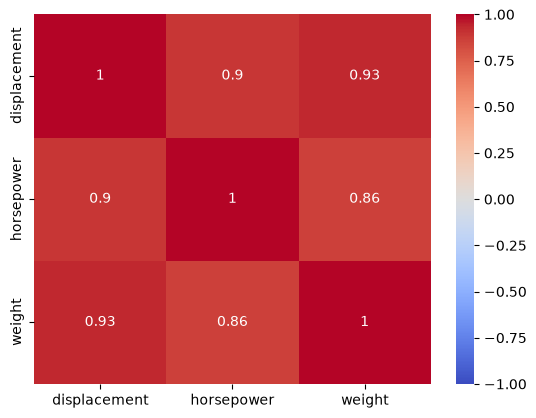

In [19]:
autocorr = auto[['displacement', 'horsepower', 'weight']].corr()
sns.heatmap(autocorr, annot = True, cmap='coolwarm', vmin=-1, vmax=1)
plt.show()

In [20]:
feats = auto[['displacement', 'horsepower', 'weight']]
print("VIF displacement: ", variance_inflation_factor(feats.values, 0))
print("VIF horsepower: ", variance_inflation_factor(feats.values, 1))
print("VIF weight: ", variance_inflation_factor(feats.values, 2))

VIF displacement:  20.242817432155874
VIF horsepower:  40.927585616185276
VIF weight:  34.350408037095725


## 1.2

(b) At k=3, forward and backward selection both select the same features. While these features aren't guaranteed to be the best features, they are likely to be good predictors of mpg.

(c) With all VIF values being well higher than 10, there is a clear risk of multicollinearity in the model. This affects backwards selection because it starts with all these correlating features and removes them one by one. Forward selection is less affected by multicollinearity because it starts with no features and adds them one by one, but it can still be affected if the features added are highly correlated.

In [23]:
# Part 2
train, test = train_test_split(auto, test_size=0.2, random_state=42)

y_train = train['mpg']
y_test = test['mpg']
cat = ['cyl_rollup', 'origin']
num = ['displacement', 'weight', 'year']

preprocess = make_column_transformer(
    (OneHotEncoder(drop="first", sparse_output=False), cat),
    remainder="passthrough",
    verbose_feature_names_out=False,
)

model_A = make_pipeline(
    StandardScaler(),
    LinearRegression()
)
model_A.fit(XA, y_train)

model_B = make_pipeline(
    preprocess,
    LinearRegression()
)
model_B.fit(XB, y_train)

df_results = pd.DataFrame({
    "Model": ["A", "B"],
    "Train RMSE": [
        root_mean_squared_error(y_train, model_A.predict(train[num])),
        root_mean_squared_error(y_train, model_B.predict(train[num + cat]))
    ],
    "Test RMSE": [
        root_mean_squared_error(y_test, model_A.predict(test[num])),
        root_mean_squared_error(y_test, model_B.predict(test[num + cat]))
    ]
})

df_results

,Model,Train RMSE,Test RMSE
0,A,3.460333,3.261195
1,B,3.225824,3.088636


## 2.1b

Model B has a lower training and testing RMSE than Model A, indicating that predictive power for MPG improves with the addition of the categorical variables. 

In [ ]:
#AI: I used AI to assist with this code.
kf5 = KFold(n_splits=5, shuffle=True, random_state=42)
kf10 = KFold(n_splits=10, shuffle=True, random_state=42)

rmse_kf5_model_A = -cross_val_score(model_A, auto[num], auto['mpg'], cv=kf5, scoring='neg_root_mean_squared_error').mean()
rmse_kf5_model_B = -cross_val_score(model_B, auto[num + cat], auto['mpg'], cv=kf5, scoring='neg_root_mean_squared_error').mean()

rmse_kf10_model_A = -cross_val_score(model_A, auto[num], auto['mpg'], cv=kf10, scoring='neg_root_mean_squared_error').mean()
rmse_kf10_model_B = -cross_val_score(model_B, auto[num + cat], auto['mpg'], cv=kf10, scoring='neg_root_mean_squared_error').mean()

print(f"5-Fold CV RMSE for Model A: {rmse_kf5_model_A:.2f}")
print(f"5-Fold CV RMSE for Model B: {rmse_kf5_model_B:.2f}")
print(f"10-Fold CV RMSE for Model A: {rmse_kf10_model_A:.2f}")
print(f"10-Fold CV RMSE for Model B: {rmse_kf10_model_B:.2f}")

5-Fold CV RMSE for Model A: 3.42
5-Fold CV RMSE for Model B: 3.23
10-Fold CV RMSE for Model A: 3.39
10-Fold CV RMSE for Model B: 3.20


(2b) As we shift from single train/test split to 5-fold and 10-fold CV, I'm noticing that the RMSE values decrease and the CV estimates stabilize.

(2c) Throughout all these tests, Model B consistently outperforms Model A with lower RMSE values, further confirming that including categorical variables improves predicitive power.

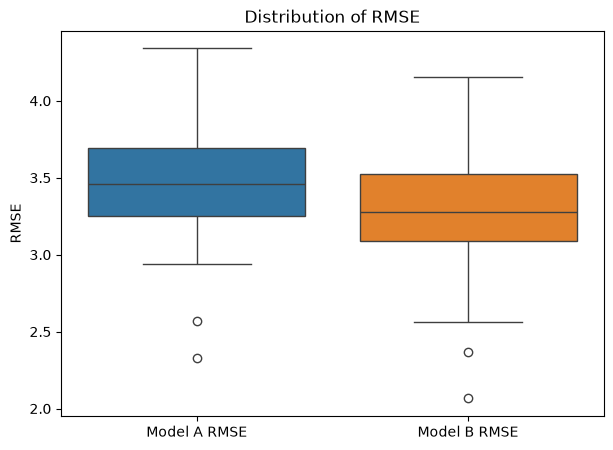

In [28]:
A_list = []
B_list = []

for seed in range(100):
    train, test = train_test_split(auto, test_size=0.2, random_state=seed)
    y_train = train['mpg']
    y_test = test['mpg']
    
    model_A.fit(train[num], y_train)
    model_B.fit(train[num + cat], y_train)
    
    A_list.append(root_mean_squared_error(y_test, model_A.predict(test[num])))
    B_list.append(root_mean_squared_error(y_test, model_B.predict(test[num + cat])))

final = pd.DataFrame({
    "Model A RMSE": A_list,
    "Model B RMSE": B_list
})

plt.figure(figsize=(7, 5))
sns.boxplot(data=final)
plt.title("Distribution of RMSE")
plt.ylabel("RMSE")
plt.show()

(a) Based on the boxplots, I'd choose Model B. It has a clear lower RMSE and an overall more stable performance despite having more predictors.

(b) Adding the categorical variables is worth the extra complexity because of the noticeable increase in predictive power.

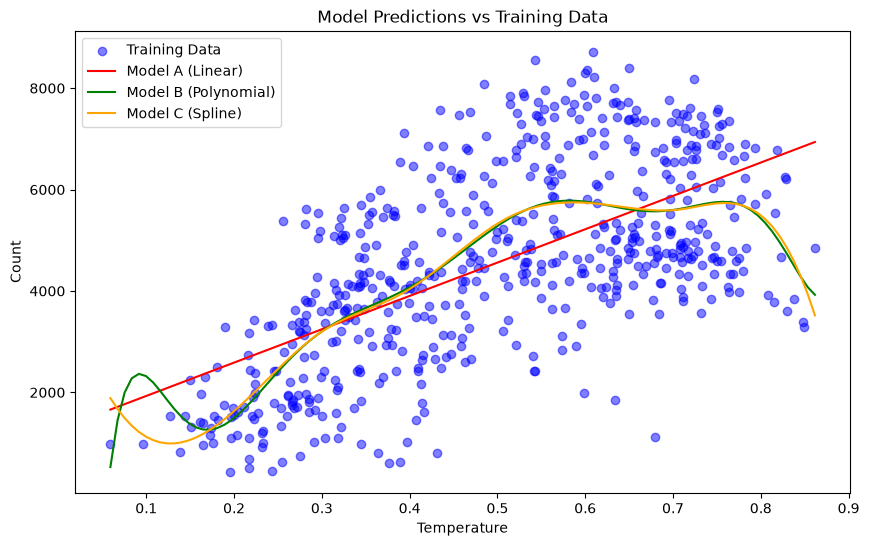

In [43]:
# Part 3
# AI: I used AI to assist with this code.
train, test = train_test_split(bike, test_size=0.2, random_state=42)

X_train = train[['temp']]
y_train = train['cnt']

X_test = test[['temp']]
y_test = test['cnt']

Model_A = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

Model_B = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=9, include_bias=False),
    LinearRegression()
)

Model_C = make_pipeline(
    SplineTransformer(degree=3, n_knots=7, knots='quantile'),
    LinearRegression()
)

Model_A.fit(X_train, y_train)
Model_B.fit(X_train, y_train)
Model_C.fit(X_train, y_train)

grid = pd.DataFrame({'temp': np.linspace(bike['temp'].min(), X_train['temp'].max(), 100)})
plt.figure(figsize=(10, 6))
plt.scatter(X_train, y_train, color='blue', alpha=0.5, label='Training Data')
plt.plot(grid, Model_A.predict(grid), color='red', label='Model A (Linear)')
plt.plot(grid, Model_B.predict(grid), color='green', label='Model B (Polynomial)')
plt.plot(grid, Model_C.predict(grid), color='orange', label='Model C (Spline)')

plt.title('Model Predictions vs Training Data')
plt.xlabel('Temperature')
plt.ylabel('Count')
plt.legend()
plt.show()

From the plot above, I'm seeing that standard linear regression doesn't capture the relationship well due to underfitting. The polynomial model actually seemd to overfit the data a bit, as seen with the curve on the left. The spline model achieves the best fit as observed by this plot.


In [37]:
train_rmse_A = root_mean_squared_error(y_train, Model_A.predict(X_train))
train_rmse_B = root_mean_squared_error(y_train, Model_B.predict(X_train))
train_rmse_C = root_mean_squared_error(y_train, Model_C.predict(X_train))

test_rmse_A = root_mean_squared_error(y_test, Model_A.predict(X_test))
test_rmse_B = root_mean_squared_error(y_test, Model_B.predict(X_test))
test_rmse_C = root_mean_squared_error(y_test, Model_C.predict(X_test))

print(f"Train RMSE - Model A: {train_rmse_A:.2f}, Model B: {train_rmse_B:.2f}, Model C: {train_rmse_C:.2f}")
print(f"Test RMSE - Model A: {test_rmse_A:.2f}, Model B: {test_rmse_B:.2f}, Model C: {test_rmse_C:.2f}")

Train RMSE - Model A: 1497.67, Model B: 1379.26, Model C: 1380.57
Test RMSE - Model A: 1546.30, Model B: 1531.56, Model C: 1532.43


(a) The model with the smallest training RMSE is Model B. The model with the smallest test RMSE is Model B as well.

(b) Decreasing the training error doesn't imply decreasing the training error. To be honest, I was expecting the polynomial model to overfit much worse than it is right now. The only real evidence I have from the plot is the polynomial curve at the bottom left.

(c) In the plot, there's clear underfitting in Model A, as this data can be represented by much more than a straight line. I think there's a bit of overfitting in Model B, but not as much as I expected.

In [44]:
train_rmse_A = root_mean_squared_error(y_train, Model_A.predict(X_train))
train_rmse_B = root_mean_squared_error(y_train, Model_B.predict(X_train))
train_rmse_C = root_mean_squared_error(y_train, Model_C.predict(X_train))

test_rmse_A = root_mean_squared_error(y_test, Model_A.predict(X_test))
test_rmse_B = root_mean_squared_error(y_test, Model_B.predict(X_test))
test_rmse_C = root_mean_squared_error(y_test, Model_C.predict(X_test))

rmse_kf5_model_A = -cross_val_score(Model_A, bike[['temp']], bike['cnt'], cv=kf5, scoring='neg_root_mean_squared_error').mean()
rmse_kf5_model_B = -cross_val_score(Model_B, bike[['temp']], bike['cnt'], cv=kf5, scoring='neg_root_mean_squared_error').mean()
rmse_kf5_model_C = -cross_val_score(Model_C, bike[['temp']], bike['cnt'], cv=kf5, scoring='neg_root_mean_squared_error').mean()

Comparison_table = pd.DataFrame({
    "Model": ["A", "B", "C"],
    "Train RMSE": [train_rmse_A, train_rmse_B, train_rmse_C],
    "Test RMSE": [test_rmse_A, test_rmse_B, test_rmse_C],
    "KF5 RMSE": [rmse_kf5_model_A, rmse_kf5_model_B, rmse_kf5_model_C]
})

Comparison_table

,Model,Train RMSE,Test RMSE,KF5 RMSE
0,A,1497.674690,1546.302650,1510.235401
1,B,1379.256517,1531.561650,1433.934679
2,C,1380.566825,1532.429891,1426.000615


This table improves my confidence in my previous answers and my original assumptions. The RMSE value for Model C is finally the lowest after using K-Fold Cross-Validation. This proves that Spline is indeed the best model for the data.

In [ ]:
# Part 4
#AI: I used AI to assist with the bootstrap code. 

X_new = pd.DataFrame({'temp': [0.60]})

predictions_A = []
predictions_B = []
predictions_C = []

np.random.seed(42)
B = 500

for i in range(B):
    bootstrap_sample = train.sample(n=len(train), replace=True)
    X_bootstrap = bootstrap_sample[['temp']]
    y_bootstrap = bootstrap_sample['cnt']
    
    Model_A.fit(X_bootstrap, y_bootstrap)
    Model_B.fit(X_bootstrap, y_bootstrap)
    Model_C.fit(X_bootstrap, y_bootstrap)
    
    predictions_A.append(Model_A.predict(X_new)[0])
    predictions_B.append(Model_B.predict(X_new)[0])
    predictions_C.append(Model_C.predict(X_new)[0])

Prediction_results = pd.DataFrame({
    "Model A Predictions": predictions_A,
    "Model B Predictions": predictions_B,
    "Model C Predictions": predictions_C
})

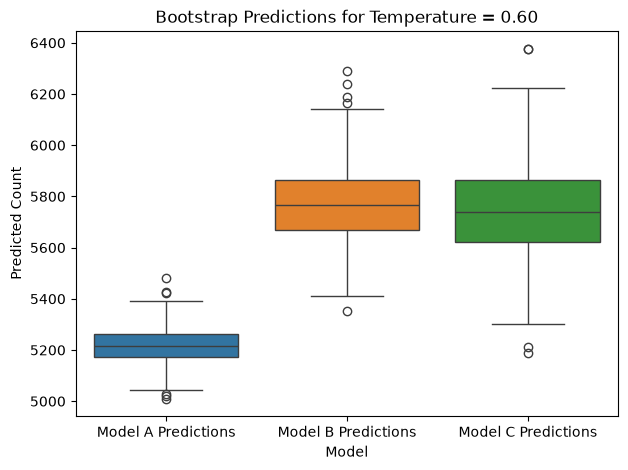

In [47]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=Prediction_results)
plt.title("Bootstrap Predictions for Temperature = 0.60")
plt.ylabel("Predicted Count")
plt.xlabel("Model")
plt.show()

## 4.1

(a) The most stable model based on these boxplots is Model A, as it shows a significantly smaller spread in predictions compared to Models B and C. The most variable model is Model C, which has the widest spread in predictions.

(b) The prediction variability is the lowest in Model A by far, followed by Model B and then Model C. At a temperature of 0.60, Model A is the best predictor and least sensitive to variations in the count of bike rentals, while Model C is the most sensitive and least reliable.

(c) If a model were to fit training observations closely, but predictions at temp=0.60 change substantially across bootstrap samples, it would indicate a severe overfitting issue. This means that the model's variance is very high and unable to generalize properly to any new data.

## 4.2

(a) Amongst models A, B, and C, the bias variance tradeoff is the most obvious in model B, followed by model C and then model A. From the RMSE values from both testing and training data, I'm seeing that model B is overfitting the most, as seen from the difference in the testing and training RMSE values. Model C is also overfitting with this observation, and model A is the least overfitting.

(b) While automatically choosing a model based on the lowest RMSE value alone is good for decreasing bias, it does not account for the bias variance tradeoff. When you instinctively select your model based on RMSE, you risk a high variance, which can lead to overfitting and a poor ability to generalize to new data. You need to select your model based on both the bias and variance. 